# What our models get out of `estimate.fits`, at best

A summary of notebooks 03–05 on one patch that holds both the satellite and its companion. We run
the 10 models of notebook 03 under the reading and brightness that work best against the true
scene in `object.fits`.

1. The scene, as the file and `object.fits` show it.
2. Choosing how to read and scale the values.
3. What the models can do, and how sure they are: with one brightness scale for the patch, and
   with the companion on its own scale.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import pvlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LogNorm, hsv_to_rgb
from astropy.io import fits
from scipy import ndimage
from omegaconf import OmegaConf

ROOT = Path("..").resolve()                       # project root
sys.path.insert(0, str(ROOT))                     # the project's src (models, dataset)
from src.data_generation import ID_TO_NAME, N_CLASSES, SpectralLibraryWarning
from src.datasets.hsi import HSIDataset
from src.registry import build_model

warnings.simplefilter("ignore", SpectralLibraryWarning)  # flagged-band reports, see notebook 01

FITS = ROOT / "assets" / "new_input" / "estimate.fits"   # what the models see
TRUTH = ROOT / "assets" / "new_input" / "object.fits"    # the true scene behind it

# logs: the project's logs on the cluster, or their sshfs mount on the Mac
LOGDIR = ROOT / "logs"
if not (LOGDIR / "estimate_10band").is_dir():
    LOGDIR = Path.home() / "_remote_data" / "satellites_remote" / "logs"
EXPDIR = LOGDIR / "estimate_10band"
config = OmegaConf.load(EXPDIR / "config.yaml")
data = HSIDataset(config.data.params)            # the generator and library the models saw
LAM = data.cfg.wavelengths_nm                    # band centres in training order: blue to red

INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8a8f", "#e4e4e2"  # text, ticks/labels, faint lines, grid
TRUE = "#00b050"                                                     # the true objects (object.fits): green
HUES = [((i * 0.618) % 1, 0.85, 0.95 if i % 2 else 0.7) for i in range(N_CLASSES - 1)]
MATERIALS = ListedColormap(["white", *(hsv_to_rgb(h) for h in HUES)])        # our 46 materials, as in 03-05
REGIONS = ListedColormap(["white", "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"])  # true A-E
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
})


def window(a, size, centre):
    # size x size pixels around centre, over the last two axes
    (y, x), h = centre, size // 2
    return a[..., y - h:y + h + 1, x - h:x + h + 1]


def show(ax, image, title, **kw):
    im = ax.imshow(image, interpolation="nearest", **kw)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=8.5)
    ax.spines[["top", "right"]].set_visible(True)
    return im


def outline(ax, mask):
    # the true objects (object.fits) as a green line on a panel
    ax.contour(mask, levels=[0.5], colors=TRUE, linewidths=1)

/Users/ppopov1/miniconda3/envs/pile/lib/python3.12/site-packages/torch/cuda/__init__.py:65: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


---
## 1. The scene

`estimate.fits` holds the values our models see; `object.fits` holds the true scene. 
We find the two objects in the file and cut a 41×41 px patch around both.

Left to right:

- The `estimate.fits`'s values summed over the bands.
- The same on a log scale, which brings out the companion.
- `object.fits` on the same log scale: a 3×16 px satellite, a single-pixel companion, and nothing
  else.

patch centre (256, 259) | object pixels in the file: satellite 54 , companion 43 | object.fits: 45 px in the patch


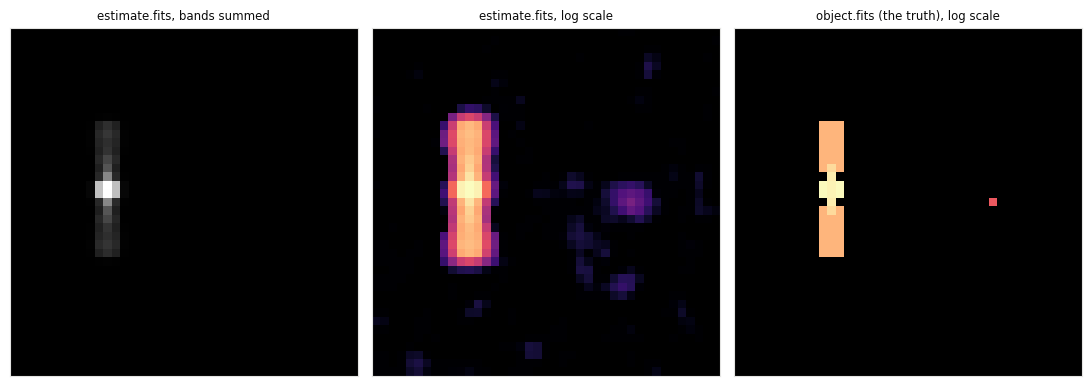

In [2]:
cube = fits.getdata(FITS).astype(float)[::-1]   # (10, 512, 512), flipped to blue -> red
total = cube.sum(0)

# the objects in the file: groups of touching non-zero pixels
groups, n = ndimage.label(total > 0, structure=np.ones((3, 3)))
satellite = groups == groups[np.unravel_index(total.argmax(), total.shape)]
totals = ndimage.sum(total, groups, range(1, n + 1))
totals[groups[satellite][0] - 1] = 0
companion = groups == totals.argmax() + 1
sat_px = satellite & (total > 0.01 * total.max())                 # the pixels each object is scaled on,
comp_px = companion & (total > 0.05 * total[companion].max())     # as in notebooks 03 and 04
middle = (np.array(ndimage.center_of_mass(total * sat_px)) + ndimage.center_of_mass(total * comp_px)) / 2
centre = tuple(int(round(v)) for v in middle)

# object.fits and its materials A-E: one spectrum per material (flat shading)
truth = fits.getdata(TRUTH).astype(float)[::-1]
true_fg = truth.sum(0) > 0
spectra = (truth[:, true_fg] / truth.sum(0)[true_fg]).round(6).T      # brightness removed
_, first, ids = np.unique(spectra, axis=0, return_index=True, return_inverse=True)
regions = np.zeros(true_fg.shape, int)                                # 0: background, 1-5: A-E
regions[true_fg] = np.argsort(np.argsort(first))[ids.ravel()] + 1     # lettered by first pixel

SIZE = 41                                        # px, the patch around both objects
tf, tr = window(true_fg, SIZE, centre), window(regions, SIZE, centre)
comp_true = window(true_fg & companion, SIZE, centre)                 # the companion in object.fits
print("patch centre", centre, "| object pixels in the file: satellite", sat_px.sum(), ", companion",
      comp_px.sum(), "| object.fits:", tf.sum(), "px in the patch")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.9))
log = LogNorm(vmin=1e-5 * total.max(), vmax=total.max())
show(axes[0], window(total, SIZE, centre), "estimate.fits, bands summed", cmap="gray")
show(axes[1], np.ma.masked_equal(window(total, SIZE, centre), 0), "estimate.fits, log scale", cmap="magma",
     norm=log)
show(axes[2], np.ma.masked_equal(window(truth.sum(0), SIZE, centre), 0), "object.fits (the truth), log scale",
     cmap="magma", norm=log)
for ax in axes[1:]:
    ax.set_facecolor("black")
fig.tight_layout()

---
## 2. Choosing how to read and scale the values

As in notebook 03, we try every combination of:

- Four readings of the file's units: `V`, `V / E`, `V / (E·Δλ)` and `V / (E·Δλ·λ)`.
- Three brightness rules: **max = 1**, **median match** and **95% match**, with one brightness
  factor for the whole patch, set on the satellite's pixels.

A pixel counts as an object when most of the 10 models give it a material, and it gets the material
most of those models give.

We score every setting by its outline IoU against `object.fits`: the overlap between the pixels
labelled as a material and the true objects (1: exact). The models normalise over their whole
input, so the IoU also depends on the window around the objects: we score each setting in windows
of 33, 41 and 61 px, and pick the one whose lowest IoU is highest.

In the figure:

- Each panel shows one setting's labels in the 41×41 px patch, with the true objects outlined in
  green.
- Titles give the IoU in this patch and, in brackets, its lowest and highest values over the
  three windows.
- The chosen setting is framed.

best setting: V / (E·Δλ) + max = 1 | IoU in the 33, 41 and 61 px windows: [0.53, 0.51, 0.42]


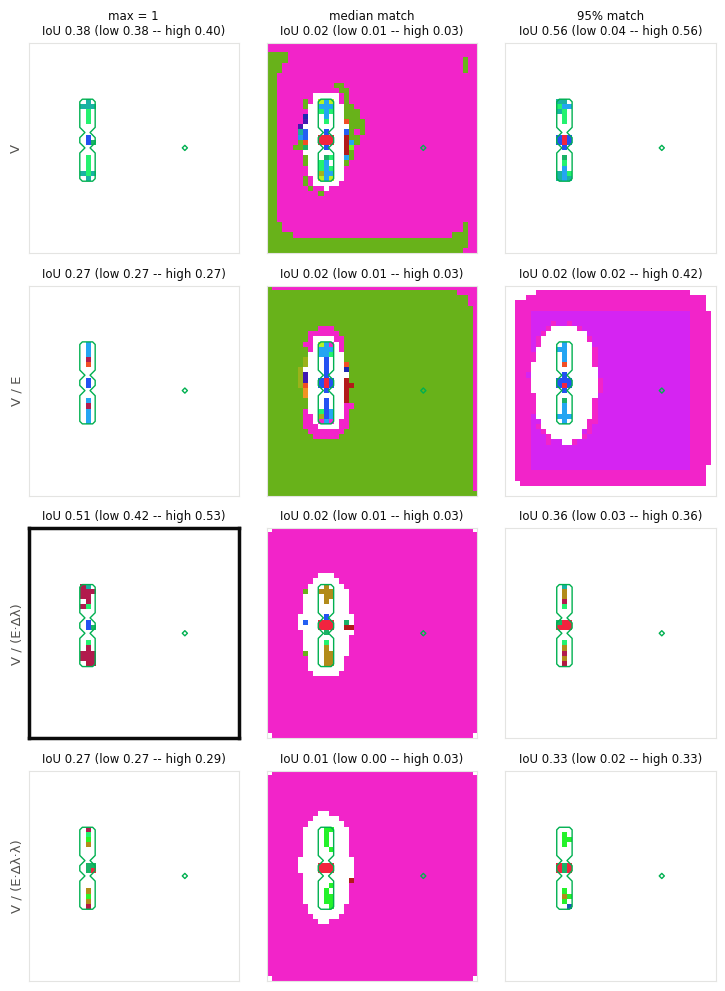

In [3]:
solar = pvlib.spectrum.get_reference_spectra(standard="ASTM G173-03")["extraterrestrial"]  # W m-2 nm-1
E = np.interp(LAM, solar.index, solar.values)    # sunlight at the band centres
DLAM = LAM ** 2 / 6400                           # band width, nm
READINGS = {"V": np.ones_like(LAM), "V / E": E, "V / (E·Δλ)": E * DLAM, "V / (E·Δλ·λ)": E * DLAM * LAM}

# brightness of our simulated satellites' pixels, for the two match rules
records = data.split("test_satellite")[(0, range(500))].values()
gen = torch.stack([r["input"] for r in records]).numpy().transpose(1, 0, 2, 3)
reference = gen[:, torch.stack([r["label"] for r in records]).numpy() > 0].mean(0)


def scales(reading, pixels):
    # the brightness factor under each rule, set on an object's pixels
    values = (cube / READINGS[reading][:, None, None])[:, pixels]
    brightness = values.mean(0)
    return {"max = 1": 1 / values.max(),
            "median match": np.median(reference) / np.median(brightness),
            "95% match": np.percentile(reference, 95) / np.percentile(brightness, 95)}


models = []
for rundir in sorted(EXPDIR.glob("run_*"), key=lambda p: int(p.name.split("_")[1])):
    model = build_model(config)
    model.load_state_dict(torch.load(rundir / "model.best.pth", map_location="cpu"))
    models.append(model.eval())


def predict(x):
    # every run's labels for a [bands, H, W] input: [runs, H, W]
    with torch.no_grad():
        t = torch.from_numpy(x[None]).float()
        return torch.stack([m(t).argmax(1)[0] for m in models]).numpy()


def combine(preds):
    # an object where most runs give a material, labelled with the material most runs give;
    # also the share of runs that call each pixel an object, and that give it its material
    counts = (preds[..., None] == np.arange(1, N_CLASSES)).sum(0)      # [H, W, 46 materials]
    objectness = (preds > 0).mean(0)
    labels = np.where(objectness >= 0.5, counts.argmax(-1) + 1, 0)
    return labels, objectness, counts.max(-1) / len(preds)


def iou(labels, true_mask):
    # overlap of the pixels labelled as a material with the true objects
    found = labels > 0
    return (found & true_mask).sum() / (found | true_mask).sum()


def ari(truth_ids, pred):
    # adjusted Rand index: 1 when the labels split the pixels like the truth, 0 at chance level
    n = pd.crosstab(truth_ids, pred).to_numpy()
    pairs = lambda counts: (counts * (counts - 1) / 2).sum()
    rows, cols = pairs(n.sum(1)), pairs(n.sum(0))
    expected = rows * cols / pairs(n.sum(keepdims=True))
    return (pairs(n) - expected) / ((rows + cols) / 2 - expected)


scores, maps = [], {}                            # IoU per setting and window, labels in the patch
for reading, divisor in READINGS.items():
    for rule, k in scales(reading, sat_px).items():
        x = cube / divisor[:, None, None] * k
        for size in (33, 41, 61):
            labels, *_ = combine(predict(window(x, size, centre)))
            scores.append({"reading": reading, "brightness": rule, "window": size,
                           "IoU": iou(labels, window(true_fg, size, centre))})
            if size == SIZE:
                maps[(reading, rule)] = labels
scores = pd.DataFrame(scores)
iou_range = scores.groupby(["reading", "brightness"])["IoU"].agg(["min", "max"])
BEST = iou_range["min"].idxmax()                 # the best worst case
best = (scores.reading == BEST[0]) & (scores.brightness == BEST[1])
print("best setting:", " + ".join(BEST), "| IoU in the 33, 41 and 61 px windows:",
      scores[best].IoU.round(2).tolist())

rules = list(scales("V", sat_px))
fig, axes = plt.subplots(len(READINGS), len(rules), figsize=(7.5, 10))
for r, reading in enumerate(READINGS):
    for c, rule in enumerate(rules):
        ax, labels = axes[r, c], maps[(reading, rule)]
        lo, hi = iou_range.loc[(reading, rule)]
        title = f"IoU {iou(labels, tf):.2f} (low {lo:.2f} -- high {hi:.2f})"
        show(ax, labels, f"{rule}\n{title}" if r == 0 else title, cmap=MATERIALS, vmin=0, vmax=N_CLASSES - 1)
        outline(ax, tf)
        if (reading, rule) == BEST:
            ax.spines[:].set_edgecolor(INK); ax.spines[:].set_linewidth(2.5)
    axes[r, 0].set_ylabel(reading, fontsize=9.5)
fig.tight_layout()


- With max = 1 (left column), no setting labels a single background pixel, in any of the three
  windows, and the window changes the IoU by 0.11 at most.
- Median match floods the background everywhere.
- 95% match depends on the window and the reading: `V` with 95% match scores best in this patch
  (0.56) but floods the background in the 33 px window (0.04), and `V / E` with 95% match floods it
  even here.

The best worst case is `V / (E·Δλ)` with max = 1 (framed): IoU 0.53, 0.51 and 0.42 in the three
windows. Notebook 03's default, `V / E` with max = 1, stays at 0.27.

---
## 3. What the models can do, and how sure they are

The best setting, in the 41×41 px patch, in two versions:

- Top row: one brightness scale for the whole patch, set on the satellite.
- Bottom row: the same, but the companion's pixels (those above 5% of its peak, as in notebook 04)
  get their own scale; on the satellite's, its values stay about 1/1000 of the satellite's.

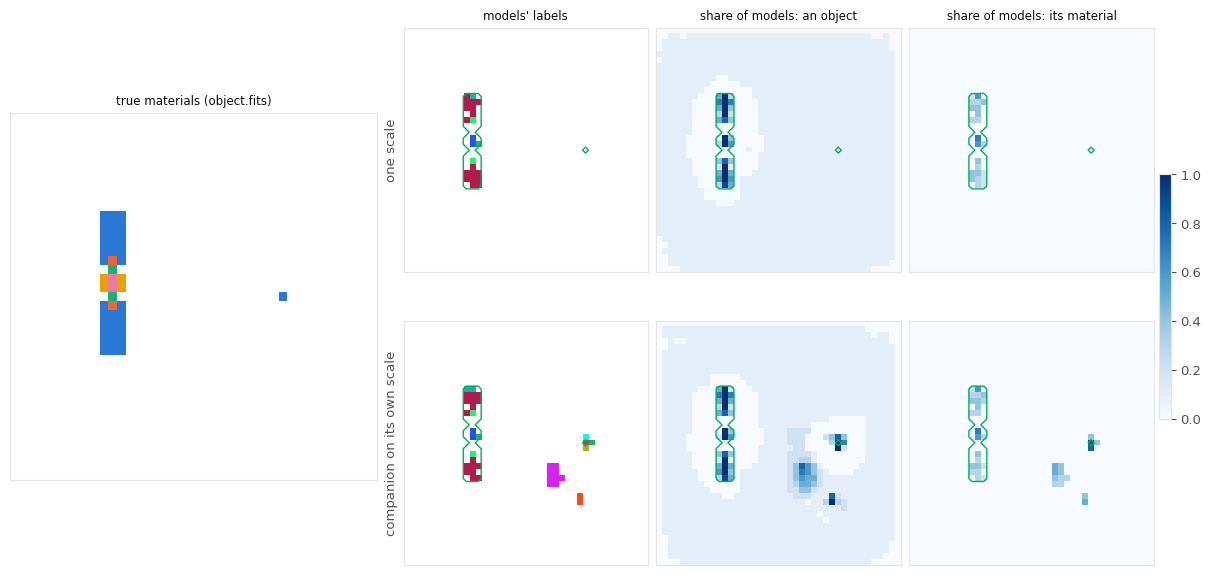

In [9]:
reading, rule = BEST
scale = np.full(total.shape, scales(reading, sat_px)[rule])
own = scale.copy()
own[comp_px] = scales(reading, comp_px)[rule]    # the companion's pixels on their own scale
results = {}
for name, k in (("one scale", scale), ("companion on its own scale", own)):
    x = cube / READINGS[reading][:, None, None] * k
    results[name] = combine(predict(window(x, SIZE, centre)))

fig, ax = plt.subplot_mosaic([["truth", "labels 0", "object 0", "material 0"],
                              ["truth", "labels 1", "object 1", "material 1"]],
                             figsize=(12, 5.8), width_ratios=[1.5, 1, 1, 1], layout="constrained")
show(ax["truth"], tr, "true materials (object.fits)", cmap=REGIONS, vmin=0, vmax=5)
for r, (name, (labels, objectness, agreement)) in enumerate(results.items()):
    top = r == 0
    show(ax[f"labels {r}"], labels, "models' labels" if top else "", cmap=MATERIALS, vmin=0, vmax=N_CLASSES - 1)
    im = show(ax[f"object {r}"], objectness, "share of models: an object" if top else "", cmap="Blues",
              vmin=0, vmax=1)
    show(ax[f"material {r}"], np.where(labels > 0, agreement, 0), "share of models: its material" if top else "",
         cmap="Blues", vmin=0, vmax=1)
    ax[f"labels {r}"].set_ylabel(name, fontsize=9.5)
    for kind in ("labels", "object", "material"):
        outline(ax[f"{kind} {r}"], tf)
fig.colorbar(im, ax=[ax["material 0"], ax["material 1"]], fraction=0.05, pad=0.02)


The maps show how sure the models are:

- They agree on where the object is. In the top row, the share of models calling a pixel an object
  is:
  - 77% on found pixels.
  - 18% on missed true pixels.
  - 8% on the background, all from one model (run 4) that labels most of it.
- They agree much less on what it is: on average, 36% of the models give a found pixel its
  material.
- Agreement isn't correctness: all 10 models call two of the companion's false pixels an object.



--------------------

And regarding materials, heck out the table below. In each row, left to right:

- The models' labels, in the colours of our 46 materials.
- The share of the 10 models that call each pixel an object.
- On the labelled pixels, the share that give it its material.


In [12]:
labels = results["one scale"][0]                 # the table: the top row, per true material
rows = []
for name, part in [*((n, (tr == k) & ~comp_true) for k, n in enumerate("ABCDE", start=1)), ("companion", comp_true)]:
    found = pd.Series(labels[part][labels[part] > 0]).map(ID_TO_NAME).value_counts()
    rows.append({"true material": name, "pixels": part.sum(), "found": found.sum(),
                 "top labels (pixels)": ", ".join(f"{k} ({v})" for k, v in found[:3].items())})
print(pd.DataFrame(rows).set_index("true material"))

               pixels  found                          top labels (pixels)
true material                                                            
A                  34     20  Black paint (16), Glass_Fiber (2), GFRP (1)
B                   2      0                                             
C                   2      0                                             
D                   4      1                               Kapton-FMT (1)
E                   2      2                              CMG_with_Cu (2)
companion           1      0                                             


---
## Summary

- **Best setting**: read the values as `V / (E·Δλ)` and scale the satellite's brightest value to 1.
  It holds across windows (IoU 0.42–0.53); the rules that use our simulator's brightness
  statistics (median and 95% match) are fragile.
- **Satellite**: at best about half of it is found, with no false pixels; the panels much better
  than the bus.
- **Materials**: on the found pixels 36% of the models agree on its material on average.
- **Companion**: invisible at the satellite's scale; on its own scale it is found, along with false
  pixels from the reconstruction's spill.
- **Confidence**: the share of models calling a pixel an object separates found, missed and
  background pixels on the satellite, but it is just as high on some false pixels around the
  companion.